<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


=== Task 1: Exact Inference (Variable Elimination) ===
Prior: P(Lung_Disease=Present)                       = 0.0822
P(Lung=Present | Xray=Pos, Cough=Yes)                = 0.8904
P(Lung=Present | Xray=Pos, Cough=Yes, Smoking=Yes)   = 0.9551
P(Lung=Present | Xray=Pos, Cough=Yes, Smoking=No)    = 0.7720

Generating 50,000 forward samples...

=== Task 5: Exact vs Approximate Inference Comparison ===
                                             Query  Exact (VE)  Forward Sample  Rejection Sample  Abs Err (Fwd)  Abs Err (Rej)
                    Prior: P(Lung_Disease=Present)      0.0822          0.0816            0.0800         0.0006         0.0022
             P(Lung=Present | Xray=Pos, Cough=Yes)      0.8904          0.8891            0.8893         0.0012         0.0010
P(Lung=Present | Xray=Pos, Cough=Yes, Smoking=Yes)      0.9551          0.9540            0.9533         0.0011         0.0018
 P(Lung=Present | Xray=Pos, Cough=Yes, Smoking=No)      0.7720          0.7735            0.

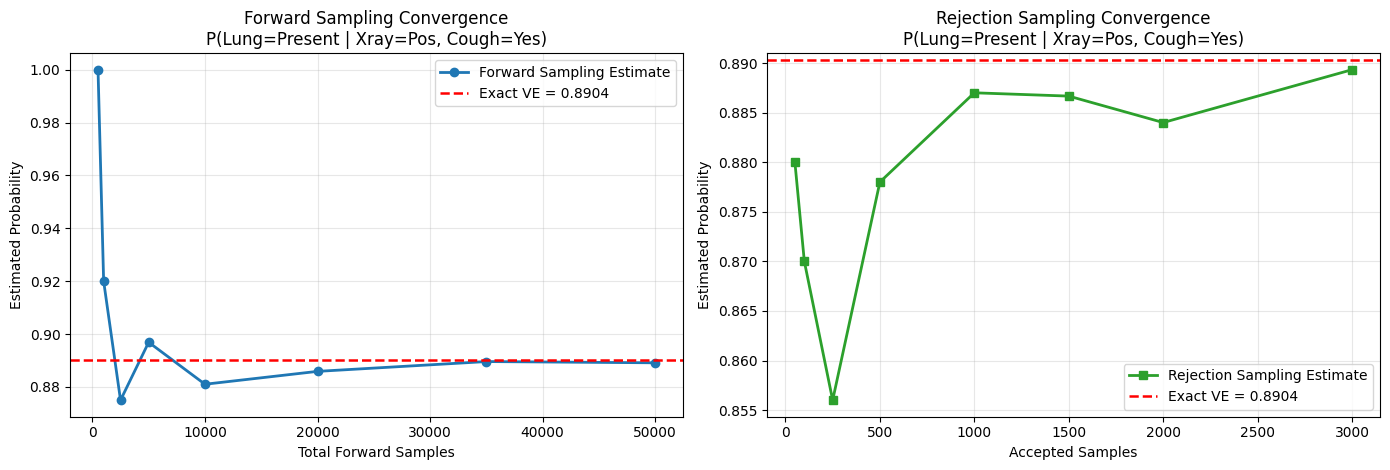

In [1]:
!pip install -q pgmpy networkx matplotlib pandas numpy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pgmpy.factors.discrete import TabularCPD, State
from pgmpy.inference import VariableElimination
from pgmpy.sampling import BayesianModelSampling

# Handle pgmpy version differences (v1.0+ uses DiscreteBayesianNetwork)
try:
    from pgmpy.models import DiscreteBayesianNetwork as BayesianNetwork
except ImportError:
    from pgmpy.models import BayesianNetwork

np.random.seed(42)

# ==========================================
# Rebuild Medical Bayesian Network (from Exp 23)
# ==========================================
model = BayesianNetwork([
    ("Smoking", "Lung_Disease"),
    ("Pollution", "Lung_Disease"),
    ("Lung_Disease", "Cough"),
    ("Lung_Disease", "Xray_Result"),
    ("Lung_Disease", "Fatigue"),
    ("Cough", "Fatigue"),
])

cpd_smoking = TabularCPD(
    "Smoking", 2, [[0.70], [0.30]],
    state_names={"Smoking": ["No", "Yes"]}
)
cpd_pollution = TabularCPD(
    "Pollution", 2, [[0.80], [0.20]],
    state_names={"Pollution": ["Low", "High"]}
)
cpd_lung = TabularCPD(
    "Lung_Disease", 2,
    [[0.98, 0.90, 0.85, 0.65],
     [0.02, 0.10, 0.15, 0.35]],
    evidence=["Smoking", "Pollution"], evidence_card=[2, 2],
    state_names={"Lung_Disease": ["Absent", "Present"], "Smoking": ["No", "Yes"], "Pollution": ["Low", "High"]}
)
cpd_cough = TabularCPD(
    "Cough", 2,
    [[0.85, 0.20],
     [0.15, 0.80]],
    evidence=["Lung_Disease"], evidence_card=[2],
    state_names={"Cough": ["No", "Yes"], "Lung_Disease": ["Absent", "Present"]}
)
cpd_xray = TabularCPD(
    "Xray_Result", 2,
    [[0.95, 0.15],
     [0.05, 0.85]],
    evidence=["Lung_Disease"], evidence_card=[2],
    state_names={"Xray_Result": ["Normal", "Positive"], "Lung_Disease": ["Absent", "Present"]}
)
cpd_fatigue = TabularCPD(
    "Fatigue", 2,
    [[0.90, 0.65, 0.40, 0.15],
     [0.10, 0.35, 0.60, 0.85]],
    evidence=["Lung_Disease", "Cough"], evidence_card=[2, 2],
    state_names={"Fatigue": ["No", "Yes"], "Lung_Disease": ["Absent", "Present"], "Cough": ["No", "Yes"]}
)

model.add_cpds(cpd_smoking, cpd_pollution, cpd_lung, cpd_cough, cpd_xray, cpd_fatigue)
assert model.check_model()

# ==========================================
# Task 1: Exact Inference with Variable Elimination
# ==========================================
infer = VariableElimination(model)

queries = [
    ("Prior: P(Lung_Disease=Present)", {}),
    ("P(Lung=Present | Xray=Pos, Cough=Yes)", {"Xray_Result": "Positive", "Cough": "Yes"}),
    ("P(Lung=Present | Xray=Pos, Cough=Yes, Smoking=Yes)", {"Xray_Result": "Positive", "Cough": "Yes", "Smoking": "Yes"}),
    ("P(Lung=Present | Xray=Pos, Cough=Yes, Smoking=No)", {"Xray_Result": "Positive", "Cough": "Yes", "Smoking": "No"}),
]

exact_results = {}
print("=== Task 1: Exact Inference (Variable Elimination) ===")
for label, ev in queries:
    q = infer.query(variables=["Lung_Disease"], evidence=ev if ev else None, show_progress=False)
    p_present = float(q.get_value(Lung_Disease="Present"))
    exact_results[label] = p_present
    print(f"{label:52s} = {p_present:.4f}")

# ==========================================
# Task 2 & 3: Forward Sampling & Rejection Sampling + Pandas Estimation
# ==========================================
sampler = BayesianModelSampling(model)
N_FORWARD = 50000
N_REJECTION = 3000

print(f"\nGenerating {N_FORWARD:,} forward samples...")
df_forward = sampler.forward_sample(size=N_FORWARD, seed=42, show_progress=False)

def estimate_from_df(df, evidence):
    sub = df.copy()
    for col, val in evidence.items():
        sub = sub[sub[col] == val]
    if len(sub) == 0:
        return np.nan
    return float((sub["Lung_Disease"] == "Present").mean())

comparison_rows = []
for label, ev in queries:
    p_exact = exact_results[label]
    p_fwd = estimate_from_df(df_forward, ev)

    if ev:
        ev_states = [State(k, v) for k, v in ev.items()]
        df_rej = sampler.rejection_sample(evidence=ev_states, size=N_REJECTION, seed=42, show_progress=False)
        p_rej = float((df_rej["Lung_Disease"] == "Present").mean())
    else:
        p_rej = float((df_forward.iloc[:N_REJECTION]["Lung_Disease"] == "Present").mean())

    comparison_rows.append({
        "Query": label,
        "Exact (VE)": round(p_exact, 4),
        "Forward Sample": round(p_fwd, 4),
        "Rejection Sample": round(p_rej, 4),
        "Abs Err (Fwd)": round(abs(p_exact - p_fwd), 4),
        "Abs Err (Rej)": round(abs(p_exact - p_rej), 4),
    })

# ==========================================
# Task 5: Compare Exact and Approximate Answers in a Table
# ==========================================
df_comp = pd.DataFrame(comparison_rows)
print("\n=== Task 5: Exact vs Approximate Inference Comparison ===")
print(df_comp.to_string(index=False))

# ==========================================
# Task 4: Plot Estimated Probability vs Sample Size (Convergence)
# ==========================================
target_label = "P(Lung=Present | Xray=Pos, Cough=Yes)"
target_ev = {"Xray_Result": "Positive", "Cough": "Yes"}
exact_target = exact_results[target_label]

sample_sizes = [500, 1000, 2500, 5000, 10000, 20000, 35000, 50000]
fwd_estimates = [estimate_from_df(df_forward.iloc[:n], target_ev) for n in sample_sizes]

# Also track rejection sampling convergence up to 3,000 accepted samples
df_rej_full = sampler.rejection_sample(
    evidence=[State("Xray_Result", "Positive"), State("Cough", "Yes")],
    size=3000, seed=42, show_progress=False
)
rej_sizes = [50, 100, 250, 500, 1000, 1500, 2000, 3000]
rej_estimates = [float((df_rej_full.iloc[:n]["Lung_Disease"] == "Present").mean()) for n in rej_sizes]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].plot(sample_sizes, fwd_estimates, marker="o", linewidth=2, label="Forward Sampling Estimate")
axes[0].axhline(exact_target, color="red", linestyle="--", linewidth=1.8, label=f"Exact VE = {exact_target:.4f}")
axes[0].set_title("Forward Sampling Convergence\nP(Lung=Present | Xray=Pos, Cough=Yes)")
axes[0].set_xlabel("Total Forward Samples")
axes[0].set_ylabel("Estimated Probability")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(rej_sizes, rej_estimates, marker="s", color="tab:green", linewidth=2, label="Rejection Sampling Estimate")
axes[1].axhline(exact_target, color="red", linestyle="--", linewidth=1.8, label=f"Exact VE = {exact_target:.4f}")
axes[1].set_title("Rejection Sampling Convergence\nP(Lung=Present | Xray=Pos, Cough=Yes)")
axes[1].set_xlabel("Accepted Samples")
axes[1].set_ylabel("Estimated Probability")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()